# Mercari Price Suggestion — Ensemble Ridge + LightGBM

Notebook ini melanjutkan baseline Ridge. Dua model yang berbeda sifatnya dilatih pada target `log1p(price)`, lalu prediksinya dirata-ratakan berbobot.

| Model | Kekuatan | Kelemahan |
|---|---|---|
| **Ridge** (linear) | Cepat, menangkap ratusan ribu kata dengan baik | Hanya menjumlahkan pengaruh fitur, tidak menangkap interaksi |
| **LightGBM** (pohon) | Menangkap interaksi (mis. brand × kategori) dan fitur numerik | Kurang efisien pada teks yang sangat jarang (sparse) |

Karena kesalahan kedua model tidak sama, rata-rata keduanya biasanya lebih akurat daripada masing-masing model sendiri.

**Alur**
1. Konfigurasi, 2. Muat data, 3. Preprocessing, 4. Fitur untuk tiap model
5. Validasi: Ridge → LightGBM → cari bobot blend terbaik
6. Latih ulang di seluruh data dan buat `submission.csv`

**Catatan memori dan waktu:** run penuh butuh sekitar 8 GB RAM atau lebih, dan LightGBM pada 1,4 juta baris bisa memakan puluhan menit. Coba dulu dengan `SAMPLE = 200_000`.
Kalau LightGBM belum terpasang: `pip install lightgbm` (di Kaggle sudah ada).

## 1. Konfigurasi dan impor

In [1]:
import gc
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

# ---------- KONFIGURASI ----------
KAGGLE_DIR = "/kaggle/input/mercari-price-suggestion-challenge"
DATA_DIR = KAGGLE_DIR if os.path.isdir(KAGGLE_DIR) else "."

TRAIN_FILE = "train.tsv"
TEST_FILE = "test.tsv"          # stage 1 (~693 ribu baris); stage 2: "test_stg2.tsv"
SUBMISSION_FILE = "submission.csv"

SAMPLE = None                   # None = seluruh data; isi angka (mis. 200_000) untuk uji cepat
RANDOM_STATE = 42
VAL_SIZE = 0.1

RIDGE_ALPHA = 3.0

LGB_PARAMS = dict(
    objective="regression",     # L2 pada target log1p == RMSLE
    learning_rate=0.1,
    n_estimators=1500,          # batas atas; early stopping menentukan jumlah sebenarnya
    num_leaves=63,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.4,
    reg_lambda=1.0,
    max_bin=63,                 # lebih sedikit bin = lebih cepat
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=-1,
)
EARLY_STOPPING_ROUNDS = 50

## 2. Memuat data

Kalau `train.tsv` belum ada, notebook mencoba mengekstrak arsip `.7z` dengan `py7zr` (`pip install py7zr`).

In [2]:
def ensure_extracted(tsv_name, archive_name):
    tsv_path = os.path.join(DATA_DIR, tsv_name)
    if os.path.exists(tsv_path):
        return tsv_path
    archive_path = os.path.join(DATA_DIR, archive_name)
    if not os.path.exists(archive_path):
        raise FileNotFoundError(f"Tidak menemukan {tsv_path} maupun {archive_path}")
    import py7zr  # pip install py7zr
    with py7zr.SevenZipFile(archive_path, "r") as z:
        z.extractall(DATA_DIR)
    return tsv_path

train = pd.read_csv(ensure_extracted(TRAIN_FILE, "train_tsv.7z"), sep="\t")
test = pd.read_csv(ensure_extracted(TEST_FILE, "test_tsv.7z"), sep="\t")

if SAMPLE:
    train = train.sample(SAMPLE, random_state=RANDOM_STATE).reset_index(drop=True)
    test = test.head(max(SAMPLE // 4, 1000)).reset_index(drop=True)

print("train:", train.shape, "| test:", test.shape)

train: (1482535, 8) | test: (693359, 7)


## 3. Preprocessing

Sama seperti baseline (buang harga ≤ 0, isi nilai kosong, pecah kategori), ditambah **fitur numerik buatan** yang berguna untuk model pohon:
panjang nama dan deskripsi, jumlah kata, penanda "tanpa deskripsi", penanda "punya brand", dan jumlah token `[rm]`
(`[rm]` menandai teks yang tadinya berupa harga, jadi penjual yang menyebut harga di teksnya meninggalkan jejak di sini).

In [3]:
NUM_COLS = ["item_condition_id", "shipping", "name_len", "desc_len", "desc_words",
            "no_desc", "has_brand", "rm_name", "rm_desc"]

def preprocess(df):
    df = df.copy()
    df["category_name"] = df["category_name"].fillna("missing/missing/missing")
    df["brand_name"] = df["brand_name"].fillna("missing")
    df["item_description"] = df["item_description"].fillna("missing")
    df["name"] = df["name"].fillna("missing")

    cats = df["category_name"].str.split("/", n=2, expand=True)
    df["cat1"] = cats[0].fillna("missing")
    df["cat2"] = cats[1].fillna("missing")
    df["cat3"] = cats[2].fillna("missing")

    # fitur numerik buatan
    df["name_len"] = df["name"].str.len()
    df["desc_len"] = df["item_description"].str.len()
    df["desc_words"] = df["item_description"].str.split().str.len()
    df["no_desc"] = df["item_description"].isin(["No description yet", "missing"]).astype(int)
    df["has_brand"] = (df["brand_name"] != "missing").astype(int)
    df["rm_name"] = df["name"].str.count(r"\[rm\]")
    df["rm_desc"] = df["item_description"].str.count(r"\[rm\]")
    return df

train = train[train["price"] > 0].reset_index(drop=True)
y = np.log1p(train["price"].values)

train = preprocess(train)
test = preprocess(test)
print("train setelah dibersihkan:", train.shape)
train[NUM_COLS].describe().T[["mean", "min", "max"]].round(2)

train setelah dibersihkan: (1481661, 18)


,mean,min,max
item_condition_id,1.91,1.0,5.0
shipping,0.45,0.0,1.0
name_len,25.79,1.0,43.0
desc_len,145.72,1.0,1046.0
desc_words,25.69,1.0,245.0
no_desc,0.06,0.0,1.0
has_brand,0.57,0.0,1.0
rm_name,0.01,0.0,6.0
rm_desc,0.15,0.0,38.0


## 4. Fitur untuk tiap model

- **Ridge** memakai matriks besar (±200 ribu kolom): kata + pasangan kata, brand, kategori, kondisi, shipping.
- **LightGBM** memakai matriks yang lebih kecil (kosakata dibatasi lebih ketat) ditambah fitur numerik. Pohon tidak perlu 200 ribu kolom,
  dan membatasinya membuat training jauh lebih cepat.

Semua vectorizer hanya di-*fit* pada data latih.

In [4]:
def build_linear_features(train_df, test_df):
    """Fitur untuk Ridge. Return (X_train, X_test) sparse CSR."""
    parts_train, parts_test = [], []

    def add(vec, col):
        parts_train.append(vec.fit_transform(train_df[col]))
        parts_test.append(vec.transform(test_df[col]))

    add(CountVectorizer(min_df=2, ngram_range=(1, 2), max_features=100_000), "name")
    add(TfidfVectorizer(ngram_range=(1, 2), max_features=200_000, stop_words="english",
                        min_df=2, sublinear_tf=True), "item_description")
    add(LabelBinarizer(sparse_output=True), "brand_name")
    for col in ["cat1", "cat2", "cat3"]:
        add(CountVectorizer(token_pattern=".+"), col)

    cond_train = pd.get_dummies(train_df[["item_condition_id", "shipping"]].astype("category"), sparse=True)
    cond_test = pd.get_dummies(test_df[["item_condition_id", "shipping"]].astype("category"), sparse=True)
    cond_test = cond_test.reindex(columns=cond_train.columns, fill_value=0)
    parts_train.append(cond_train.sparse.to_coo().tocsr())
    parts_test.append(cond_test.sparse.to_coo().tocsr())

    return hstack(parts_train).tocsr(), hstack(parts_test).tocsr()


def build_tree_features(train_df, test_df):
    """Fitur untuk LightGBM: kosakata lebih kecil + fitur numerik. Float32 supaya hemat memori."""
    parts_train, parts_test = [], []

    def add(vec, col):
        parts_train.append(vec.fit_transform(train_df[col]).astype(np.float32))
        parts_test.append(vec.transform(test_df[col]).astype(np.float32))

    add(CountVectorizer(min_df=5, max_features=20_000), "name")
    add(TfidfVectorizer(ngram_range=(1, 2), max_features=50_000, stop_words="english",
                        min_df=5, sublinear_tf=True), "item_description")
    add(CountVectorizer(token_pattern=".+", min_df=3), "brand_name")
    for col in ["cat1", "cat2", "cat3"]:
        add(CountVectorizer(token_pattern=".+"), col)

    parts_train.append(csr_matrix(train_df[NUM_COLS].values.astype(np.float32)))
    parts_test.append(csr_matrix(test_df[NUM_COLS].values.astype(np.float32)))

    return (hstack(parts_train, format="csr", dtype=np.float32),
            hstack(parts_test, format="csr", dtype=np.float32))


def rmsle(y_true_log, y_pred_log):
    """Target sudah di-log1p, jadi RMSLE = RMSE di ruang log."""
    return np.sqrt(np.mean((y_true_log - y_pred_log) ** 2))

## 5. Validasi lokal (hold-out 10%)

### 5a. Ridge

In [5]:
t0 = time.time()
tr_idx, va_idx = train_test_split(np.arange(len(train)), test_size=VAL_SIZE, random_state=RANDOM_STATE)
y_tr, y_va = y[tr_idx], y[va_idx]
df_tr, df_va = train.iloc[tr_idx], train.iloc[va_idx]

Xl_tr, Xl_va = build_linear_features(df_tr, df_va)
print("Fitur Ridge:", Xl_tr.shape)

ridge = Ridge(alpha=RIDGE_ALPHA, solver="auto", random_state=RANDOM_STATE).fit(Xl_tr, y_tr)
val_ridge = ridge.predict(Xl_va)
print(f"Ridge     RMSLE: {rmsle(y_va, val_ridge):.5f}   ({time.time() - t0:.0f} detik)")

del Xl_tr, Xl_va, ridge
gc.collect();

Fitur Ridge: (1333494, 305675)
Ridge     RMSLE: 0.43932   (993 detik)


### 5b. LightGBM (dengan early stopping pada data validasi)

In [6]:
t0 = time.time()
Xt_tr, Xt_va = build_tree_features(df_tr, df_va)
print("Fitur LightGBM:", Xt_tr.shape)

gbm = lgb.LGBMRegressor(**LGB_PARAMS)
gbm.fit(
    Xt_tr, y_tr,
    eval_set=[(Xt_va, y_va)],
    eval_metric="rmse",
    callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=True), lgb.log_evaluation(100)],
)
best_iter = gbm.best_iteration_ or LGB_PARAMS["n_estimators"]
val_lgb = gbm.predict(Xt_va)
print(f"LightGBM  RMSLE: {rmsle(y_va, val_lgb):.5f}   iterasi terbaik: {best_iter}   ({time.time() - t0:.0f} detik)")

del Xt_tr, Xt_va, gbm
gc.collect();

Fitur LightGBM: (1333494, 73895)
Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 0.510536	valid_0's l2: 0.260647
[200]	valid_0's rmse: 0.486008	valid_0's l2: 0.236204
[300]	valid_0's rmse: 0.474058	valid_0's l2: 0.224731
[400]	valid_0's rmse: 0.466474	valid_0's l2: 0.217598
[500]	valid_0's rmse: 0.461372	valid_0's l2: 0.212865
[600]	valid_0's rmse: 0.457427	valid_0's l2: 0.209239
[700]	valid_0's rmse: 0.454241	valid_0's l2: 0.206335
[800]	valid_0's rmse: 0.451554	valid_0's l2: 0.203901
[900]	valid_0's rmse: 0.449286	valid_0's l2: 0.201858
[1000]	valid_0's rmse: 0.447319	valid_0's l2: 0.200094
[1100]	valid_0's rmse: 0.445884	valid_0's l2: 0.198813
[1200]	valid_0's rmse: 0.444384	valid_0's l2: 0.197477
[1300]	valid_0's rmse: 0.443096	valid_0's l2: 0.196334
[1400]	valid_0's rmse: 0.44204	valid_0's l2: 0.1954
[1500]	valid_0's rmse: 0.441098	valid_0's l2: 0.194567
Did not meet early stopping. Best iteration is:
[1500]	valid_0's rmse: 0.441098	valid_0's l2:

### 5c. Cari bobot blend terbaik

`prediksi = w × LightGBM + (1 − w) × Ridge`. Bobot dipilih dengan mencoba w dari 0 sampai 1 pada data validasi.
(Early stopping memakai data validasi yang sama, jadi skor blend sedikit optimis. Selisihnya biasanya kecil.)

Ridge saja     : 0.43932
LightGBM saja  : 0.44110
Blend terbaik  : 0.42660   (bobot LightGBM = 0.50)


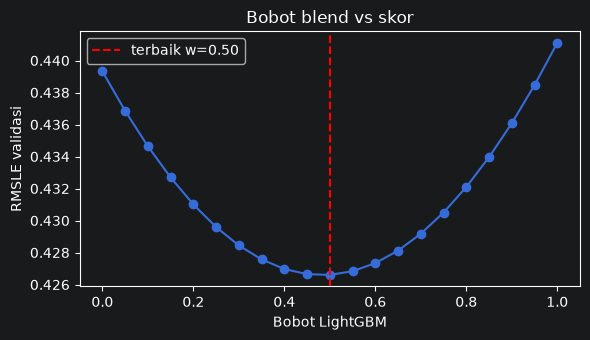

In [7]:
weights = np.linspace(0, 1, 21)
scores = np.array([rmsle(y_va, w * val_lgb + (1 - w) * val_ridge) for w in weights])
best_w = float(weights[scores.argmin()])

print(f"Ridge saja     : {scores[0]:.5f}")
print(f"LightGBM saja  : {scores[-1]:.5f}")
print(f"Blend terbaik  : {scores.min():.5f}   (bobot LightGBM = {best_w:.2f})")

plt.figure(figsize=(6, 3.5))
plt.plot(weights, scores, marker="o")
plt.axvline(best_w, color="red", linestyle="--", label=f"terbaik w={best_w:.2f}")
plt.xlabel("Bobot LightGBM")
plt.ylabel("RMSLE validasi")
plt.title("Bobot blend vs skor")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Latih ulang di seluruh data dan buat submission

Kedua model dilatih ulang pada 100% data latih. LightGBM tidak punya data validasi lagi untuk early stopping,
jadi jumlah pohonnya diambil dari `best_iter` × 1,1 (data lebih banyak, sedikit pohon tambahan wajar).

In [ ]:
t0 = time.time()

# --- Ridge ---
Xl_full, Xl_test = build_linear_features(train, test)
ridge = Ridge(alpha=RIDGE_ALPHA, solver="auto", random_state=RANDOM_STATE).fit(Xl_full, y)
pred_ridge = ridge.predict(Xl_test)
del Xl_full, Xl_test, ridge
gc.collect()
print(f"Ridge selesai ({time.time() - t0:.0f} detik)")

# --- LightGBM ---
Xt_full, Xt_test = build_tree_features(train, test)
final_params = {**LGB_PARAMS, "n_estimators": max(int(best_iter * 1.1), 50)}
gbm = lgb.LGBMRegressor(**final_params).fit(Xt_full, y)
pred_lgb = gbm.predict(Xt_test)
del Xt_full, Xt_test, gbm
gc.collect()
print(f"LightGBM selesai ({time.time() - t0:.0f} detik)")

# --- Blend ---
pred_log = best_w * pred_lgb + (1 - best_w) * pred_ridge
pred = np.expm1(pred_log).clip(min=3)       # harga minimum di data = 3 USD

submission = pd.DataFrame({"test_id": test["test_id"], "price": pred})
submission.to_csv(SUBMISSION_FILE, index=False)

# simpan prediksi tiap model (log-scale) untuk blend dengan model lain nanti
np.save("pred_ridge_log.npy", pred_ridge)
np.save("pred_lgb_log.npy", pred_lgb)

print(f"Tersimpan: {SUBMISSION_FILE} {submission.shape}  (total {time.time() - t0:.0f} detik)")
submission.head()

Ridge selesai (396 detik)


## Langkah berikutnya

1. **Tuning LightGBM:** `num_leaves`, `colsample_bytree`, `learning_rate` lebih kecil (0,05) dengan `n_estimators` lebih besar.
2. **Stacking:** pakai prediksi Ridge out-of-fold sebagai fitur tambahan untuk LightGBM. Biasanya lebih kuat daripada blend sederhana.
3. **Tambah MLP sparse** sebagai model ketiga. `pred_ridge_log.npy` dan `pred_lgb_log.npy` sudah tersimpan untuk blend tiga model.
4. **Fitur lebih kaya:** kata kunci khusus ("bundle", "lot", "new with tags"), jumlah tanda seru, dan rasio huruf kapital.